# Unveiling Customer Insights: Amazon Customers’ Reviews Analysis with LDA and VADER

Seminar project – *Machine Learning in Economics and Finance*. Author: Md Tanjib Mahmud.

**Question:** which topics do Amazon customers write about, and how positive or negative are the reviews in each topic?

**Pipeline:** sample 10,000 reviews → clean / lemmatise → bigrams & trigrams → dictionary + bag-of-words → LDA for several topic counts and hyper-parameters → pick the model with the highest C_v coherence → pyLDAvis → VADER sentiment per dominant topic → check VADER against the dataset's own polarity label.

**Data:** [Amazon Reviews Polarity (Kaggle)](https://www.kaggle.com/datasets/kritanjalijain/amazon-reviews). Put `train.csv` at `data/amazon_review.csv` (see `data/README.md`). The CSV has **no header**: `polarity` (1 = negative, 2 = positive), `title`, `review`.

### Design notes
- **Reproducibility:** one `SEED` is used for the sample and for every LDA model; the single-process `LdaModel` is used because the multi-worker `LdaMulticore` is not exactly reproducible even with a seed.
- **One corpus type:** raw bag-of-words counts (the input LDA assumes) are used for training, coherence, pyLDAvis and the assignment of reviews to topics.
- **Vocabulary:** rare and very common tokens are filtered and a small, switchable list of generic words is removed.
- **Model comparison:** every model gets a C_v coherence score, and the selected model is the single object used for all later steps.
- **Sentiment:** topic-level sentiment is reported with review counts, and VADER is checked against the dataset's own polarity label.
- **Portability:** paths are relative, and the notebook runs locally or in Colab.

> **All numbers are produced by running this notebook – none are typed in.** Re-run it top to bottom to regenerate them.

## 1. Setup

In [1]:
# Run once if the packages are missing (restart the kernel afterwards):
# %pip install -r ../requirements.txt

In [2]:
import os, re, json, random, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from gensim import corpora
from gensim.models import LdaModel
from gensim.models.coherencemodel import CoherenceModel
from gensim.models.phrases import Phrases, Phraser
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis

for res in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
    nltk.download(res, quiet=True)

warnings.filterwarnings("ignore", category=FutureWarning)

In [3]:
# ---------------- configuration ----------------
SEED          = 42        # used for sampling AND every LDA model
SAMPLE_SIZE   = int(os.environ.get("SAMPLE_SIZE", 10_000))
PASSES        = int(os.environ.get("LDA_PASSES", 10))
K_VALUES      = [5, 8, 10, 15, 20, 30]       # topic counts compared
HYPER_K       = [5, 10, 15]                  # topic counts used for the alpha/eta search
# (alpha, eta); (symmetric, symmetric) is already in the K grid. eta="auto" is left out on purpose: in gensim's
# LdaModel it does not change the fitted topics (checked: identical topic-word matrices), so it would only duplicate runs.
HYPER_GRID    = [("asymmetric", "symmetric"), ("auto", "symmetric"), (0.01, 0.01), (10, 10)]

# dictionary filtering and generic words (set USE_EXTRA_STOPWORDS=False to switch the word list off)
NO_BELOW, NO_ABOVE = 5, 0.5
USE_EXTRA_STOPWORDS = True
EXTRA_STOPWORDS = {"one", "like", "would", "could", "get", "got", "also", "even", "much", "really",
                   "good", "great", "well", "thing", "make", "ever", "still", "back", "way"}

random.seed(SEED); np.random.seed(SEED)

# Optional cache: if the environment variable LDA_CACHE_DIR is set, the sample and every trained model are
# stored there and reused by later runs (useful for slow machines). Delete the folder after changing the
# preprocessing or the configuration above. Without the variable nothing is cached.
CACHE_DIR = Path(os.environ["LDA_CACHE_DIR"]) if os.environ.get("LDA_CACHE_DIR") else None
if CACHE_DIR:
    CACHE_DIR.mkdir(parents=True, exist_ok=True)

# paths work from the repo root, from notebooks/, and in Colab
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS_DIR = ROOT / "results"; (RESULTS_DIR / "figures").mkdir(parents=True, exist_ok=True)
CANDIDATES = [os.environ.get("AMAZON_CSV"),
              ROOT / "data" / "amazon_review.csv",
              ROOT / "data" / "train.csv",
              "/content/drive/MyDrive/Colab Notebooks/amazon_review_polarity_csv/amazon_review.csv"]
DATA_PATH = next((Path(p) for p in CANDIDATES if p and Path(p).exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found. Put train.csv at data/amazon_review.csv "
                            "(see data/README.md) or set the AMAZON_CSV environment variable.")
print("Using data file:", DATA_PATH)

Using data file: data/amazon_review.csv


## 2. Load a random sample
The file has no header row. To avoid holding millions of reviews in memory, rows are sampled while reading, then reduced to exactly `SAMPLE_SIZE` rows.

In [4]:
COLS = ["polarity", "title", "review"]
sample_cache = CACHE_DIR / f"sample_{SAMPLE_SIZE}_{SEED}.pkl" if CACHE_DIR else None

if sample_cache is not None and sample_cache.exists():
    df_sample, n_rows = pd.read_pickle(sample_cache)
else:
    n_rows = sum(1 for _ in open(DATA_PATH, encoding="utf-8", errors="ignore"))
    frac = min(1.0, SAMPLE_SIZE * 1.3 / n_rows)
    parts = []
    for chunk in pd.read_csv(DATA_PATH, header=None, names=COLS, chunksize=500_000):
        parts.append(chunk.sample(frac=frac, random_state=SEED))
    pool = pd.concat(parts).dropna(subset=["review"])
    df_sample = pool.sample(n=min(SAMPLE_SIZE, len(pool)), random_state=SEED).reset_index(drop=True)
    if sample_cache is not None:
        pd.to_pickle((df_sample, n_rows), sample_cache)

print(f"Rows in file: {n_rows:,} | rows in sample: {len(df_sample):,}")
print(f"Median review length: {int(df_sample['review'].str.split().str.len().median())} words")
print(df_sample["polarity"].value_counts(normalize=True).rename({1: "negative (1)", 2: "positive (2)"}).round(3))
df_sample.head()

Rows in file: 3,600,000 | rows in sample: 10,000
Median review length: 66 words
polarity
negative (1)    0.503
positive (2)    0.497
Name: proportion, dtype: float64


,polarity,title,review
0,2,THIS RULES!,I think the best thing about this game is that...
1,2,pretty and effective,I got these to hide the ugle burners on my sto...
2,2,Classic Christmas movie,Watched this movie with my kids and wanted to ...
3,2,Complex Plot,Dawn was a teaser that made you want to read t...
4,1,Who needs this?,I don't mean to put the song itself down. It's...


## 3. Preprocessing
Lower-case, tokenise, keep alphabetic tokens, remove stop words, lemmatise. The dataset stores line breaks as the two characters `\n`; these are replaced by spaces first.

In [5]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words("english"))
if USE_EXTRA_STOPWORDS:
    stop_words |= EXTRA_STOPWORDS

def preprocess_text(text):
    text = str(text).replace("\\n", " ").lower()
    return [lemmatizer.lemmatize(tok) for tok in word_tokenize(text)
            if tok.isalpha() and tok not in stop_words]

df_sample["tokens"] = df_sample["review"].apply(preprocess_text)
df_sample[["review", "tokens"]].head()

,review,tokens
0,I think the best thing about this game is that...,"[think, best, game, goldeneye, original, plot,..."
1,I got these to hide the ugle burners on my sto...,"[hide, ugle, burner, stove, give, pretty, look..."
2,Watched this movie with my kids and wanted to ...,"[watched, movie, kid, wanted, grand, child, cl..."
3,Dawn was a teaser that made you want to read t...,"[dawn, teaser, made, want, read, second, book,..."
4,I don't mean to put the song itself down. It's...,"[mean, put, song, pretty, though, nothing, com..."


## 4. Bigrams and trigrams

In [6]:
bigram_mod  = Phraser(Phrases(df_sample["tokens"], min_count=5, threshold=100))
trigram_mod = Phraser(Phrases(bigram_mod[df_sample["tokens"]], min_count=5, threshold=100))
df_sample["tokens_ngram"] = [trigram_mod[bigram_mod[doc]] for doc in df_sample["tokens"]]

phrase_counts = Counter(t for doc in df_sample["tokens_ngram"] for t in doc if "_" in t)
print(f"{len(phrase_counts)} distinct phrases found. Most frequent:")
pd.DataFrame(phrase_counts.most_common(20), columns=["phrase", "count"])

206 distinct phrases found. Most frequent:


,phrase,count
0,waste_money,176
1,highly_recommend,150
2,year_ago,123
3,main_character,93
4,customer_service,72
5,save_money,66
6,highly_recommended,51
7,looking_forward,51
8,ca_wait,51
9,month_ago,50


## 5. Dictionaries and corpora
Both versions (unigrams only / with n-grams) use the **same raw bag-of-words representation**. TF-IDF is deliberately not used because LDA models word counts. Rare (< `NO_BELOW` documents) and very common (> `NO_ABOVE` of documents) tokens are removed; reviews that end up empty are dropped.

In [7]:
def build(tokens_col):
    d = corpora.Dictionary(df_sample[tokens_col])
    d.filter_extremes(no_below=NO_BELOW, no_above=NO_ABOVE)
    return d, [d.doc2bow(t) for t in df_sample[tokens_col]]

dict_uni, bow_uni = build("tokens")
dict_ng,  bow_ng  = build("tokens_ngram")

keep = [i for i, (a, b) in enumerate(zip(bow_uni, bow_ng)) if a and b]
print(f"Dropping {len(df_sample) - len(keep)} reviews that are empty after filtering")
df_sample = df_sample.iloc[keep].reset_index(drop=True)
bow_uni = [bow_uni[i] for i in keep]
bow_ng  = [bow_ng[i]  for i in keep]

DATA = {   # everything needed to train / score / visualise a model, per corpus type
    "unigram": dict(dictionary=dict_uni, corpus=bow_uni, texts=df_sample["tokens"].tolist()),
    "ngram":   dict(dictionary=dict_ng,  corpus=bow_ng,  texts=df_sample["tokens_ngram"].tolist()),
}
print(f"Documents: {len(df_sample):,} | vocabulary: unigram {len(dict_uni):,}, with n-grams {len(dict_ng):,}")

Dropping 1 reviews that are empty after filtering
Documents: 9,999 | vocabulary: unigram 6,410, with n-grams 6,554


## 6. LDA experiments
A single helper trains a model and computes its C_v coherence. `LdaModel` (single process) with a fixed `random_state` makes the runs repeatable.

**Part A** compares topic counts with and without n-grams (alpha = eta = `symmetric`).
**Part B** varies alpha / eta on the n-gram corpus.

In [8]:
RESULTS, MODELS = [], {}

def train_and_score(kind, k, alpha="symmetric", eta="symmetric"):
    name = f"{kind}|k={k}|alpha={alpha}|eta={eta}"
    d = DATA[kind]
    key = re.sub(r"[^A-Za-z0-9_.=-]", "_",
                 f"{name}_seed{SEED}_passes{PASSES}_docs{len(d['corpus'])}_vocab{len(d['dictionary'])}_extra{USE_EXTRA_STOPWORDS}")
    model_file = CACHE_DIR / f"{key}.model" if CACHE_DIR else None
    score_file = CACHE_DIR / f"{key}.json" if CACHE_DIR else None

    if CACHE_DIR and model_file.exists() and score_file.exists():      # reuse a finished model
        model = LdaModel.load(str(model_file))
        coh = json.loads(score_file.read_text())["coherence_cv"]
    else:
        model = LdaModel(corpus=d["corpus"], id2word=d["dictionary"], num_topics=k, alpha=alpha, eta=eta,
                         passes=PASSES, random_state=SEED, chunksize=2000, eval_every=None)
        coh = CoherenceModel(model=model, texts=d["texts"], dictionary=d["dictionary"],
                             coherence="c_v", processes=1).get_coherence()
        if CACHE_DIR:
            model.save(str(model_file)); score_file.write_text(json.dumps({"coherence_cv": coh}))
    MODELS[name] = (model, kind)
    RESULTS.append(dict(name=name, corpus=kind, k=k, alpha=alpha, eta=eta, coherence_cv=coh))
    print(f"{name:55s} C_v = {coh:.4f}")

# Part A – number of topics, with / without n-grams
for kind in ["unigram", "ngram"]:
    for k in K_VALUES:
        train_and_score(kind, k)

unigram|k=5|alpha=symmetric|eta=symmetric               C_v = 0.4931
unigram|k=8|alpha=symmetric|eta=symmetric               C_v = 0.5257
unigram|k=10|alpha=symmetric|eta=symmetric              C_v = 0.4800
unigram|k=15|alpha=symmetric|eta=symmetric              C_v = 0.4674
unigram|k=20|alpha=symmetric|eta=symmetric              C_v = 0.4383
unigram|k=30|alpha=symmetric|eta=symmetric              C_v = 0.4257
ngram|k=5|alpha=symmetric|eta=symmetric                 C_v = 0.5387
ngram|k=8|alpha=symmetric|eta=symmetric                 C_v = 0.5196
ngram|k=10|alpha=symmetric|eta=symmetric                C_v = 0.4489
ngram|k=15|alpha=symmetric|eta=symmetric                C_v = 0.4619
ngram|k=20|alpha=symmetric|eta=symmetric                C_v = 0.4607
ngram|k=30|alpha=symmetric|eta=symmetric                C_v = 0.4150


In [9]:
# Part B – alpha / eta search on the n-gram corpus
for k in HYPER_K:
    for alpha, eta in HYPER_GRID:
        train_and_score("ngram", k, alpha, eta)

ngram|k=5|alpha=asymmetric|eta=symmetric                C_v = 0.5020
ngram|k=5|alpha=auto|eta=symmetric                      C_v = 0.5356
ngram|k=5|alpha=0.01|eta=0.01                           C_v = 0.5139
ngram|k=5|alpha=10|eta=10                               C_v = 0.2984
ngram|k=10|alpha=asymmetric|eta=symmetric               C_v = 0.4565
ngram|k=10|alpha=auto|eta=symmetric                     C_v = 0.4294
ngram|k=10|alpha=0.01|eta=0.01                          C_v = 0.4377
ngram|k=10|alpha=10|eta=10                              C_v = 0.2735
ngram|k=15|alpha=asymmetric|eta=symmetric               C_v = 0.4708
ngram|k=15|alpha=auto|eta=symmetric                     C_v = 0.4582
ngram|k=15|alpha=0.01|eta=0.01                          C_v = 0.4564
ngram|k=15|alpha=10|eta=10                              C_v = 0.2733


### Coherence overview

,corpus,k,alpha,eta,coherence_cv
0,ngram,5,symmetric,symmetric,0.5387
1,ngram,5,auto,symmetric,0.5356
2,unigram,8,symmetric,symmetric,0.5257
3,ngram,8,symmetric,symmetric,0.5196
4,ngram,5,0.01,0.01,0.5139
5,ngram,5,asymmetric,symmetric,0.5020
6,unigram,5,symmetric,symmetric,0.4931
7,unigram,10,symmetric,symmetric,0.4800
8,ngram,15,asymmetric,symmetric,0.4708
9,unigram,15,symmetric,symmetric,0.4674


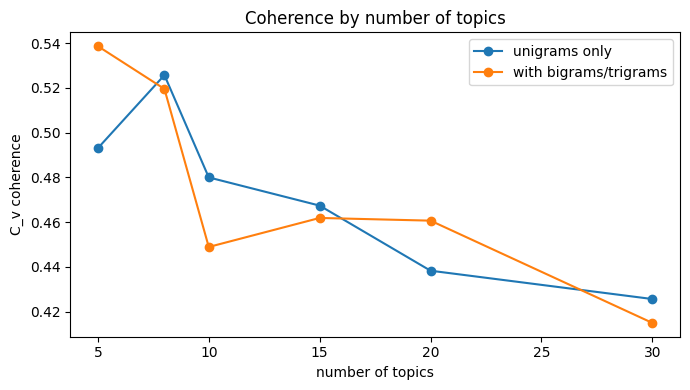

In [10]:
results = pd.DataFrame(RESULTS).sort_values("coherence_cv", ascending=False).reset_index(drop=True)
results.to_csv(RESULTS_DIR / "coherence_results.csv", index=False)
display(results.drop(columns="name").round(4))

# topic count vs coherence (alpha = eta = symmetric)
base = results[(results.alpha == "symmetric") & (results.eta == "symmetric")]
fig, ax = plt.subplots(figsize=(7, 4))
for kind, label in [("unigram", "unigrams only"), ("ngram", "with bigrams/trigrams")]:
    s = base[base.corpus == kind].sort_values("k")
    ax.plot(s.k, s.coherence_cv, marker="o", label=label)
ax.set_xlabel("number of topics"); ax.set_ylabel("C_v coherence"); ax.set_title("Coherence by number of topics")
ax.legend(); fig.tight_layout(); fig.savefig(RESULTS_DIR / "figures" / "coherence_by_k.png", dpi=150); plt.show()

## 7. Select the best model
The model with the highest C_v coherence is selected. **Every later step uses this one object.** Note that coherence is one criterion among several: look at the topics and the pyLDAvis map before relying on the choice, and remember that differences of a few hundredths are within what another random seed could change.

In [11]:
best_name = results.loc[0, "name"]
best_model, best_kind = MODELS[best_name]
best_data = DATA[best_kind]
print("Selected model:", best_name, f"(C_v = {results.loc[0, 'coherence_cv']:.4f})")

topic_words = pd.DataFrame({
    "topic": range(best_model.num_topics),
    "top_words": [", ".join(w for w, _ in best_model.show_topic(t, topn=10)) for t in range(best_model.num_topics)],
})
display(topic_words)

Selected model: ngram|k=5|alpha=symmetric|eta=symmetric (C_v = 0.5387)


,topic,top_words
0,0,"book, read, story, author, reading, time, life..."
1,1,"movie, film, time, see, watch, love, dvd, show..."
2,2,"game, use, play, work, better, buy, need, time..."
3,3,"album, cd, song, music, sound, love, best, fan..."
4,4,"product, work, bought, use, time, used, amazon..."


## 8. pyLDAvis (interactive topic map)
`sort_topics=False` keeps pyLDAvis topic *n+1* identical to model topic *n*, so the numbers match the tables below.

In [12]:
vis = gensimvis.prepare(best_model, best_data["corpus"], best_data["dictionary"], sort_topics=False)
pyLDAvis.save_html(vis, str(RESULTS_DIR / "lda_visualization_best_model.html"))
print("Saved:", RESULTS_DIR / "lda_visualization_best_model.html")
pyLDAvis.display(vis)

Saved: results/lda_visualization_best_model.html


## 9. VADER sentiment by dominant topic
VADER is applied to the **original** review text (capitalisation and punctuation carry signal). Each review gets the topic with the highest probability under `best_model`, computed on the same bag-of-words corpus the model was trained on. Categories: positive ≥ 0.05, negative ≤ −0.05, otherwise neutral.

In [13]:
analyzer = SentimentIntensityAnalyzer()
df_sample["compound"] = df_sample["review"].apply(lambda t: analyzer.polarity_scores(str(t).replace("\\n", " "))["compound"])
df_sample["sentiment_category"] = np.select(
    [df_sample["compound"] >= 0.05, df_sample["compound"] <= -0.05],
    ["Positive", "Negative"], default="Neutral")

def dominant_topic(bow):
    probs = best_model.get_document_topics(bow, minimum_probability=0.0)
    t, p = max(probs, key=lambda x: x[1])
    return t, p

dom = [dominant_topic(b) for b in best_data["corpus"]]
df_sample["dominant_topic"]      = [t for t, _ in dom]
df_sample["dominant_topic_prob"] = [p for _, p in dom]

print("Overall sentiment categories:")
print(df_sample["sentiment_category"].value_counts(normalize=True).round(3))

Overall sentiment categories:
sentiment_category
Positive    0.708
Negative    0.258
Neutral     0.035
Name: proportion, dtype: float64


In [14]:
MIN_REVIEWS = 30   # topics with fewer reviews are flagged as unreliable
g = df_sample.groupby("dominant_topic")
topic_sentiment = pd.DataFrame({
    "n_reviews": g.size(),
    "mean_compound": g["compound"].mean(),
    "share_positive": g["sentiment_category"].apply(lambda s: (s == "Positive").mean()),
    "share_neutral":  g["sentiment_category"].apply(lambda s: (s == "Neutral").mean()),
    "share_negative": g["sentiment_category"].apply(lambda s: (s == "Negative").mean()),
}).join(topic_words.set_index("topic"))
topic_sentiment["low_n"] = topic_sentiment["n_reviews"] < MIN_REVIEWS
topic_sentiment = topic_sentiment.sort_values("mean_compound", ascending=False)
topic_sentiment.to_csv(RESULTS_DIR / "topic_sentiment_summary.csv")
display(topic_sentiment.round(3))

,n_reviews,mean_compound,share_positive,share_neutral,share_negative,top_words,low_n
dominant_topic,,,,,,,
3,1523,0.558,0.814,0.022,0.164,"album, cd, song, music, sound, love, best, fan...",False
0,3017,0.412,0.732,0.030,0.238,"book, read, story, author, reading, time, life...",False
2,968,0.359,0.704,0.048,0.249,"game, use, play, work, better, buy, need, time...",False
4,2809,0.298,0.656,0.047,0.297,"product, work, bought, use, time, used, amazon...",False
1,1682,0.286,0.658,0.026,0.316,"movie, film, time, see, watch, love, dvd, show...",False


### Example reviews per topic
The three reviews with the highest topic probability in each topic. They are meant to help *interpret and label* the topics (labels are a subjective step).

In [15]:
ex = (df_sample.sort_values("dominant_topic_prob", ascending=False)
               .groupby("dominant_topic").head(3)
               .sort_values(["dominant_topic", "dominant_topic_prob"], ascending=[True, False]))
ex_out = ex[["dominant_topic", "dominant_topic_prob", "compound", "review"]].copy()
ex_out["review"] = ex_out["review"].str.replace("\\n", " ", regex=False).str.slice(0, 300)
ex_out.to_csv(RESULTS_DIR / "topic_example_reviews.csv", index=False)
with pd.option_context("display.max_colwidth", 300):
    display(ex_out.round(3))

,dominant_topic,dominant_topic_prob,compound,review
119,0,0.989,0.957,"Seventy Times Seven is a wonderful read. One encounters spiritual conflict and self doubt, sexual tension and love in the context of a gay Brother who has yet to take his final vows in the Catholic Church. Vito, the conflicted Brother is a fully formed character. The author does not bash the Cat..."
18,0,0.989,-0.422,"This is a terrible book.This book claims to be a self-help book for people suffering from serious mental illness. However, the authors do not rely on any research to support the methods described in the book. Instead of relying on current research, the book seems to be based on principals of psy..."
7105,0,0.988,0.961,"If you think charter schools are the panacea for public education you are wrong. Charter schools do about as well as public schools. Except, they are part of the corporatization of American education (and everything else for that matter). Our country was founded on the idea of free and public ed..."
193,1,0.987,-0.313,"My nephews and I are big fans of the Men In Black films, at least the first two. We were a bit disappointed at this third one. We missed it at the theaters so we were anxious for the DVD release.Besides being thoroughly grossed out a couple of times and tempted to shut it off and switch to somet..."
128,1,0.987,-0.834,Please do not let the people you love watch this film! You have been warned. This movie made me so frustrated and annoyed. I felt like I was trapped in somebody's nightmare and could not escape for an hour and a half... Please DO NOT watch this film if you're bored. It will make you feel like br...
4099,1,0.987,0.952,"Being a fan of any giant robots i.e. Transformers, and Robobtech, I expected to like this film. However I did not expect to love it, as well as not expecting to get a little choked up at the ending. I don't usually get so caught up in a movie, that I will shed a tear for the character, but the c..."
1910,2,0.988,0.978,"I'm a coffee snob. I admit it.I love great coffee, no matter the form. I've been known to roast my own, and will drive long distances to visit the shops that I like. I'll also go to great lengths to brew my own cup just right. Of course, I'm also eager to try something new.That said, this was a ..."
292,2,0.984,0.273,This game is the worst jurassic park operation genesis. I would recommend the pc or xbox version. Yes u get 25 dinosaurs to CHOSE from but not to have all at ONCE. you can only get 3 dig sites oh lets see in every dig site u get 3 diffenrnt dinosaurs so a total of 9 dinos in a park. Thats right ...
3982,2,0.976,0.334,These games really bring back memories. I never was really into video games until I found these games and got absolutely obsessed with them. I think that this set would be a good start if you've never played the sims games before at all.You can't beat a game and it's seven expansions on four dis...
3429,3,0.991,-0.813,"Lo primero que se me viene a la mente al escuchar este segundo disco de Sean es a su papa, es inevitable, ademas creo que el tiene mucho mas derecho en imitarlo, o mas que imitarlo, en seguir ciertos parametros de su musica. Si en el mundo de la musica son muchos que los copian, porque no el hij..."


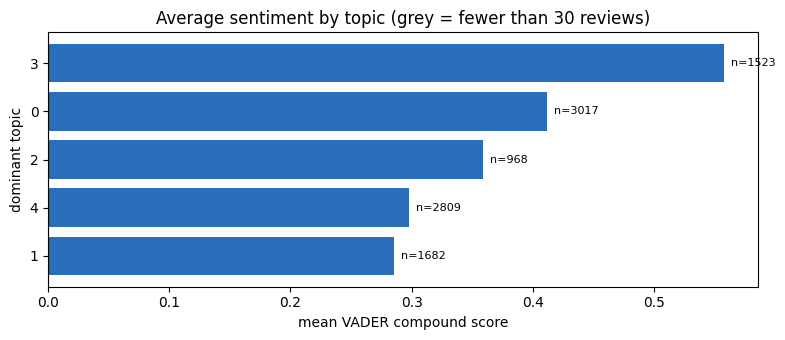

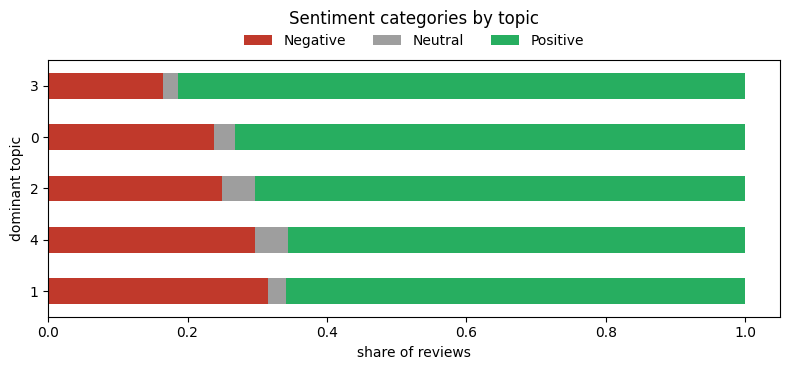

In [16]:
ts = topic_sentiment.sort_values("mean_compound")
fig, ax = plt.subplots(figsize=(8, 0.4 * len(ts) + 1.5))
colors = ["#b0b0b0" if low else "#2a6fbb" for low in ts["low_n"]]
ax.barh(ts.index.astype(str), ts["mean_compound"], color=colors)
for y, (v, n) in enumerate(zip(ts["mean_compound"], ts["n_reviews"])):
    ax.text(v, y, f"  n={n}", va="center", ha="left" if v >= 0 else "right", fontsize=8)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("mean VADER compound score"); ax.set_ylabel("dominant topic")
ax.set_title(f"Average sentiment by topic (grey = fewer than {MIN_REVIEWS} reviews)")
fig.tight_layout(); fig.savefig(RESULTS_DIR / "figures" / "sentiment_by_topic.png", dpi=150); plt.show()

shares = topic_sentiment.loc[ts.index, ["share_negative", "share_neutral", "share_positive"]]
shares.columns = ["Negative", "Neutral", "Positive"]
ax = shares.plot(kind="barh", stacked=True, figsize=(8, 0.4 * len(ts) + 1.8),
                 color=["#c0392b", "#9e9e9e", "#27ae60"])
ax.set_xlabel("share of reviews"); ax.set_ylabel("dominant topic")
ax.set_title("Sentiment categories by topic", pad=26)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)
plt.tight_layout(); plt.savefig(RESULTS_DIR / "figures" / "sentiment_shares_by_topic.png", dpi=150); plt.show()

## 10. How reliable is VADER here?
The dataset labels each review positive (2) or negative (1) from its star rating. Comparing VADER with this label gives a rough accuracy check (neutral VADER scores are reported separately).

In [17]:
vader_label = np.where(df_sample["compound"] >= 0.05, 2, np.where(df_sample["compound"] <= -0.05, 1, 0))
cm = pd.crosstab(df_sample["polarity"].rename("dataset label (1=neg, 2=pos)"),
                 pd.Series(vader_label, name="VADER (0=neutral)"))
display(cm)

decided = vader_label != 0
acc = (vader_label[decided] == df_sample["polarity"].to_numpy()[decided]).mean()
print(f"VADER neutral on {(~decided).mean():.1%} of reviews")
print(f"Accuracy on the remaining {decided.mean():.1%}: {acc:.1%}")

VADER (0=neutral),0,1,2
"dataset label (1=neg, 2=pos)",,,
1,247,2249,2531
2,101,326,4545


VADER neutral on 3.5% of reviews
Accuracy on the remaining 96.5%: 70.4%


## 11. Limitations
- 10,000 of ~3.6 million reviews; topics and sentiment may change with another sample or seed.
- LDA topics from short reviews overlap; labelling topics is a subjective step.
- Coherence differences of a few hundredths should not be over-interpreted (re-run with other `SEED` values to check stability).
- VADER is lexicon-based (sarcasm, domain language); see the accuracy check above.
- A review's *dominant* topic ignores that reviews mix topics (`dominant_topic_prob` shows how clear the assignment is).